## Data preparation and data cleaning

In [51]:
import numpy as np
import pandas as pd

train = pd.read_csv('./ML-MATT-CompetitionQT2021_train.csv', sep=';')
test = pd.read_csv('./ML-MATT-CompetitionQT2021_test.csv', sep=';')

display(train.head())

,Time,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
0,10:45,3BLTE,12.3848,1.4019,0.3927,0.0438,16.6522,0.6806,1.1293,1.0491,5,3,8,1
1,9:45,1BLTE,22.0438,2.0016,0.5620,0.2697,10.3994,1.1771,1.4480,1.1630,6,5,11,1
2,7:45,9BLTE,0.5105,0.4258,0.0152,0.0106,0.2755,0.1685,1.0379,1.0535,1,2,3,1
3,2:45,4ALTE,1.9963,1.1513,0.9908,0.0245,64.7465,0.8747,1.0766,1.0526,3,2,5,1
4,3:30,10BLTE,0.3030,0.4040,0.0160,0.0130,0.3480,0.1680,1.0110,1.0110,2,1,3,0


In [18]:
# Check results
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (36904, 14)
Test shape: (9158, 13)


In [52]:
# Check missing values
print("Missing values:", train.isnull().sum().sum())

# Check duplicates
print("Duplicates:", train.duplicated().sum())

# Remove duplicates from training
train = train.drop_duplicates().reset_index(drop=True)

# Convert time into numerical values
for data in [train, test]:
    time = pd.to_datetime(data["Time"], format="%H:%M")
    data["Hour"] = time.dt.hour + time.dt.minute / 60

# Remove original Time column
train.drop(columns=["Time"], inplace=True)
test.drop(columns=["Time"], inplace=True)

display(train.head())

# Check results
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Missing values: 0
Duplicates: 103


,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual,Hour
0,3BLTE,12.3848,1.4019,0.3927,0.0438,16.6522,0.6806,1.1293,1.0491,5,3,8,1,10.75
1,1BLTE,22.0438,2.0016,0.5620,0.2697,10.3994,1.1771,1.4480,1.1630,6,5,11,1,9.75
2,9BLTE,0.5105,0.4258,0.0152,0.0106,0.2755,0.1685,1.0379,1.0535,1,2,3,1,7.75
3,4ALTE,1.9963,1.1513,0.9908,0.0245,64.7465,0.8747,1.0766,1.0526,3,2,5,1,2.75
4,10BLTE,0.3030,0.4040,0.0160,0.0130,0.3480,0.1680,1.0110,1.0110,2,1,3,0,3.50


Train shape: (36801, 14)
Test shape: (9158, 13)


In [20]:
# Class distribution (%)
print(train["Unusual"].value_counts(normalize=True) * 100)

Unusual
0    72.329556
1    27.670444
Name: proportion, dtype: float64


## EDA, feature importance analysis

In [3]:
# Data types and missing values
train.info()

# Descriptive statistics
display(train.describe().T)

# Number of distinct cells
print("Distinct cells:", train["CellName"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36801 entries, 0 to 36800
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CellName     36801 non-null  object 
 1   PRBUsageUL   36801 non-null  float64
 2   PRBUsageDL   36801 non-null  float64
 3   meanThr_DL   36801 non-null  float64
 4   meanThr_UL   36801 non-null  float64
 5   maxThr_DL    36801 non-null  float64
 6   maxThr_UL    36801 non-null  float64
 7   meanUE_DL    36801 non-null  float64
 8   meanUE_UL    36801 non-null  float64
 9   maxUE_DL     36801 non-null  int64  
 10  maxUE_UL     36801 non-null  int64  
 11  maxUE_UL+DL  36801 non-null  int64  
 12  Unusual      36801 non-null  int64  
 13  Hour         36801 non-null  float64
dtypes: float64(9), int64(4), object(1)
memory usage: 3.9+ MB


,count,mean,std,min,25%,50%,75%,max
PRBUsageUL,36801.0,7.919810,8.474274,0.0,1.2130,4.5725,12.328,51.3330
PRBUsageDL,36801.0,2.129249,2.263073,0.0,0.7070,1.3944,2.829,77.5050
meanThr_DL,36801.0,0.566980,0.733736,0.0,0.1431,0.3580,0.726,19.6010
meanThr_UL,36801.0,0.068364,0.188067,0.0,0.0220,0.0400,0.075,12.4610
maxThr_DL,36801.0,17.976725,15.864070,0.0,5.8360,14.3461,25.331,148.4785
maxThr_UL,36801.0,1.813817,5.084888,0.0,0.3690,0.7130,1.255,49.6906
meanUE_DL,36801.0,1.187873,0.204978,0.0,1.0533,1.1320,1.273,3.0354
meanUE_UL,36801.0,0.673520,0.540066,0.0,0.0100,1.0120,1.069,2.6680
maxUE_DL,36801.0,4.332219,1.773769,0.0,3.0000,4.0000,6.000,13.0000
maxUE_UL,36801.0,3.133257,1.395183,0.0,2.0000,3.0000,4.000,12.0000


Distinct cells: 33


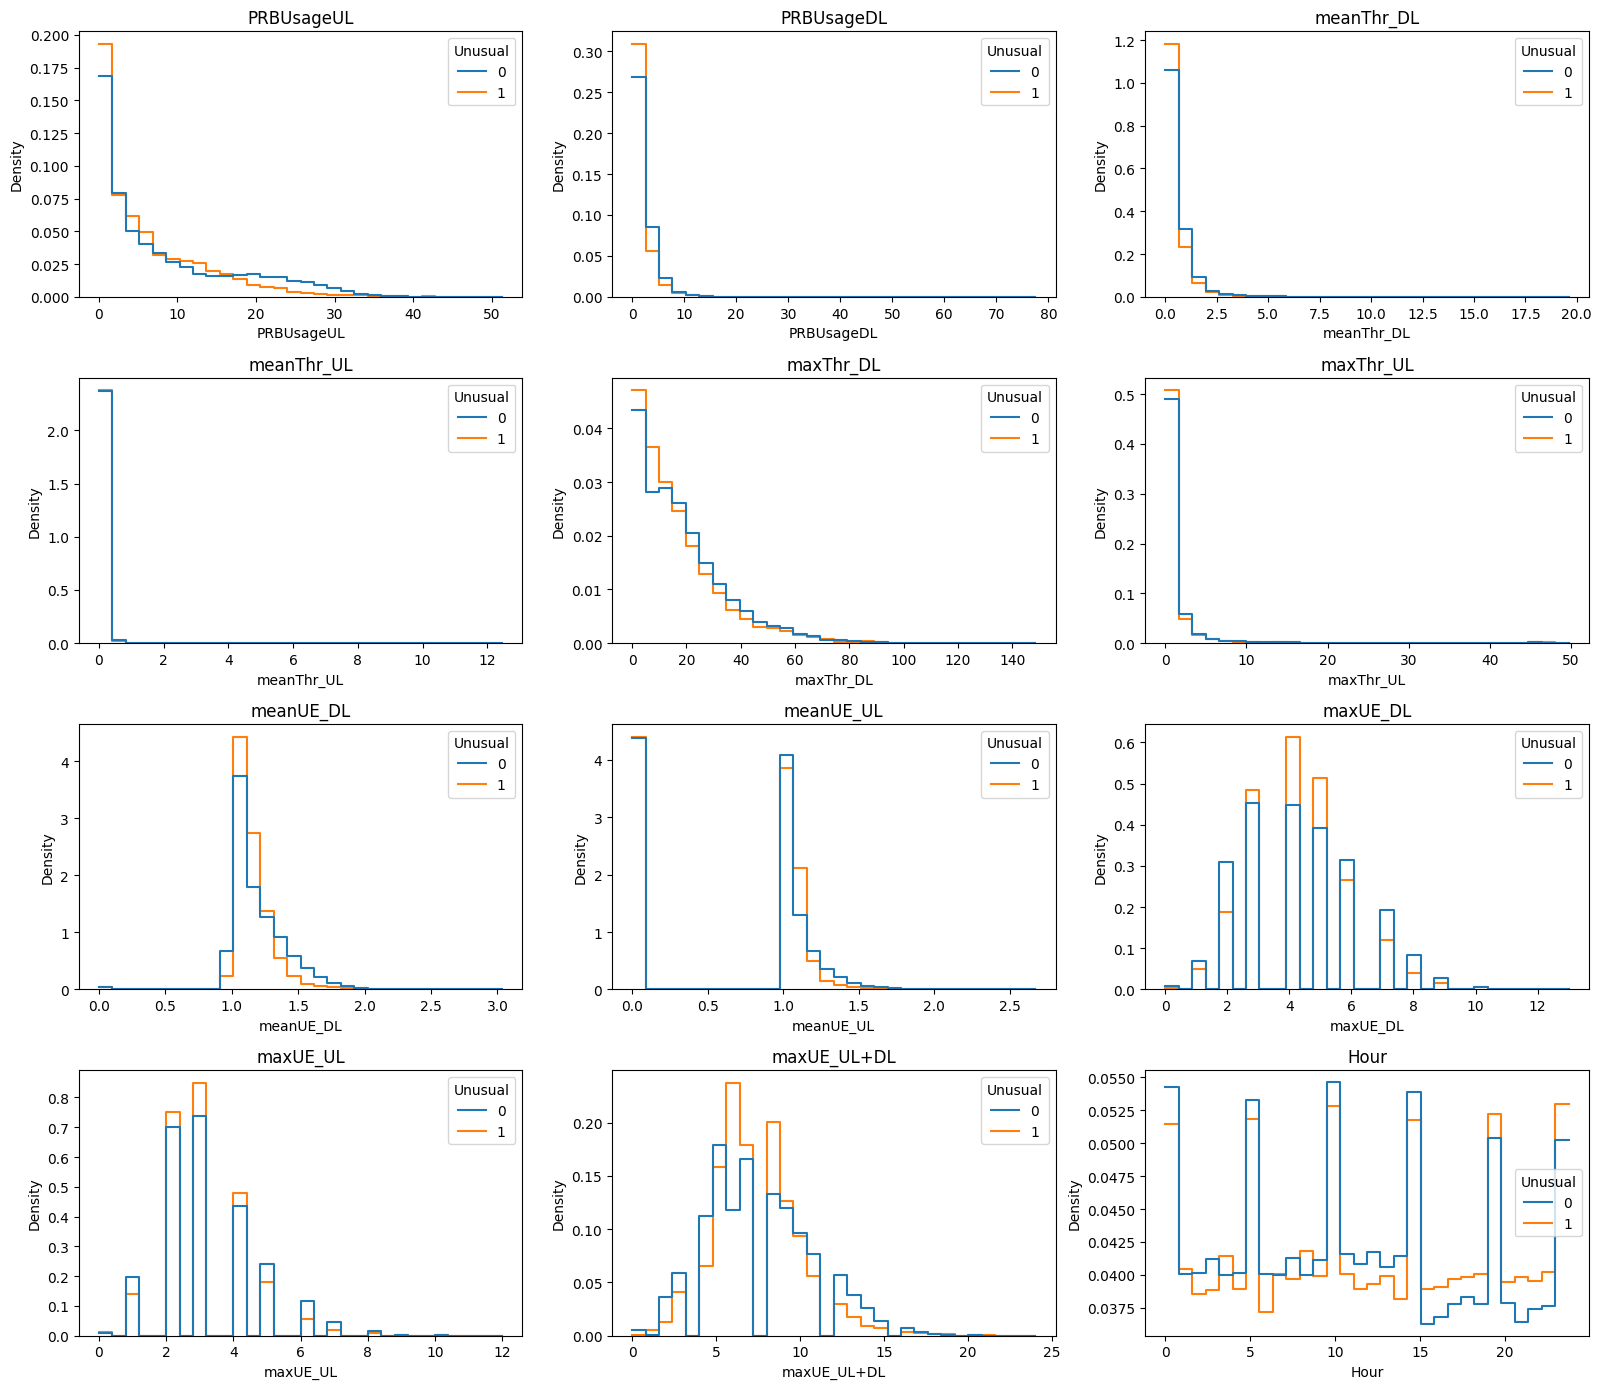

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

features = train.select_dtypes(include="number").columns.drop("Unusual")

fig, axes = plt.subplots(
    (len(features) + 2) // 3, 3,
    figsize=(16, 14)
)

for ax, feature in zip(axes.flat, features):
    sns.histplot(
        data=train,
        x=feature,
        hue="Unusual",
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=ax
    )
    ax.set_title(feature)

for ax in axes.flat[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

,Count,Unusual_rate
HourBin,,
0,1558,26.636714
1,1557,27.745665
2,1540,26.818182
3,1588,27.644836
4,1536,26.953125
5,1553,27.044430
6,1536,26.888021
7,1575,27.174603
8,1574,28.144854


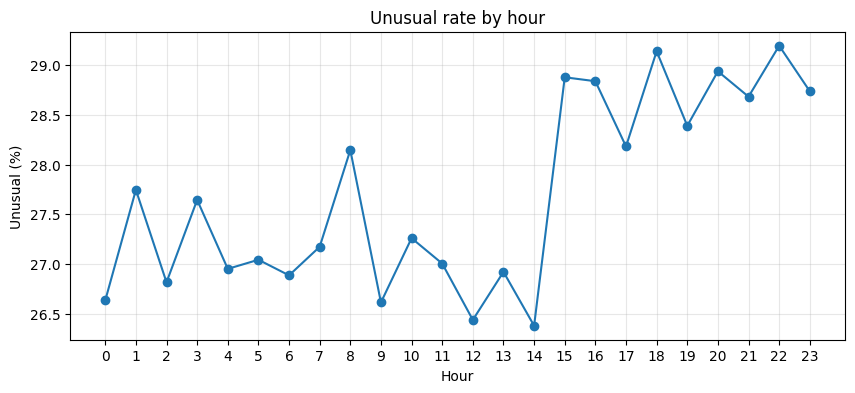

In [7]:
hour_summary = (
    train.assign(HourBin=train["Hour"].astype(int))
    .groupby("HourBin")["Unusual"]
    .agg(Count="size", Unusual_rate="mean")
)

hour_summary["Unusual_rate"] *= 100

display(hour_summary)

hour_summary["Unusual_rate"].plot(
    marker="o",
    figsize=(10, 4)
)

plt.title("Unusual rate by hour")
plt.xlabel("Hour")
plt.ylabel("Unusual (%)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

,Count,Unusual_rate
CellName,,
2ALTE,1013,30.898322
5BLTE,1104,28.894928
10CLTE,1117,28.648165
7ALTE,1083,28.439520
5CLTE,1131,28.381963
6VLTE,1134,28.306878
6WLTE,1133,28.243601
3BLTE,1117,28.200537
5ALTE,1157,28.176318


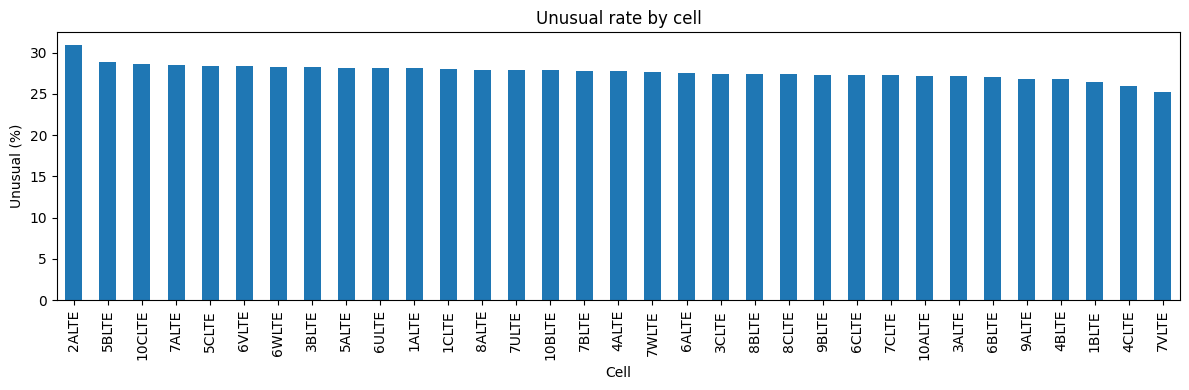

In [8]:
cell_summary = (
    train.groupby("CellName")["Unusual"]
    .agg(Count="size", Unusual_rate="mean")
)

cell_summary["Unusual_rate"] *= 100
cell_summary = cell_summary.sort_values("Unusual_rate", ascending=False)

display(cell_summary)

cell_summary["Unusual_rate"].plot.bar(figsize=(12, 4))

plt.title("Unusual rate by cell")
plt.xlabel("Cell")
plt.ylabel("Unusual (%)")
plt.tight_layout()
plt.show()

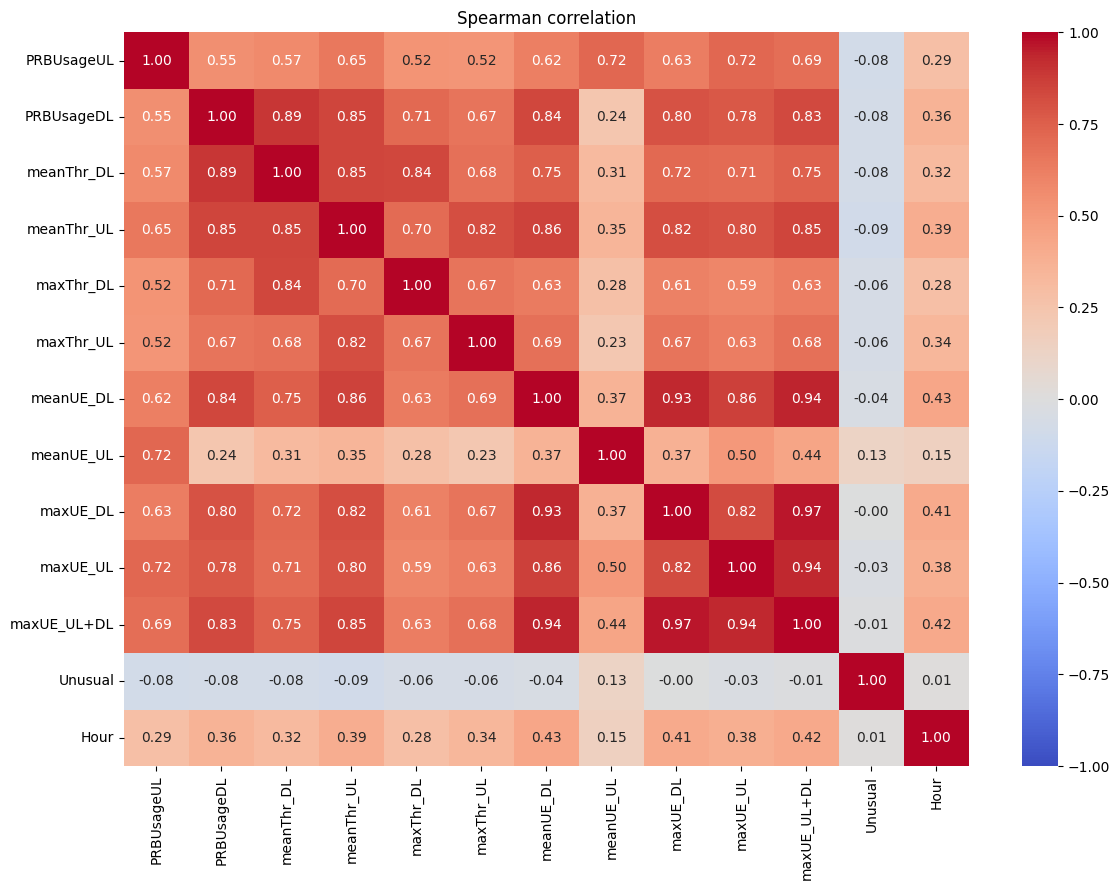

In [9]:
correlation = train.select_dtypes(include="number").corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman correlation")
plt.tight_layout()
plt.show()

## Model selection process and parameter tuning

In [38]:
import numpy as np
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_predict
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, precision_recall_curve
)

# 1. Features and target — use the already prepared data
X = train.drop(columns=["Unusual", "CellName", "maxUE_UL+DL"])
y = train["Unusual"]

# 2. Split: 80% training and 20% internal testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    shuffle=True,
    stratify=y,
    random_state=42
)

# 5. Hyperparameter search
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7, 1.0],
    "class_weight": [
    None,
    "balanced",
    "balanced_subsample",
    {0: 1, 1: 2},
    {0: 1, 1: 3},
    {0: 1, 1: 10}
]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=1
)

search.fit(x_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validation F1: {search.best_score_:.4f}")

# 6. Evaluate on the reserved 20%
best_model = search.best_estimator_

# Choose threshold using out-of-fold probabilities on training data
oof_proba = cross_val_predict(
    best_model,
    x_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

# Align precision and recall with thresholds
precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / (precision + recall + 1e-12)

best_idx = np.argmax(f1)
threshold = thresholds[best_idx]

print(f"Chosen threshold: {threshold:.4f}")
print(
    f"OOF precision: {precision[best_idx]:.4f} | "
    f"recall: {recall[best_idx]:.4f} | "
    f"F1: {f1[best_idx]:.4f}"
)

for name, x_data, y_data in [
    ("TRAIN", x_train, y_train),
    ("TEST", x_test, y_test)
]:
    y_proba = best_model.predict_proba(x_data)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    print(f"\n{'=' * 40}")
    print(f"{name} RESULTS")
    print(f"{'=' * 40}")

    print("\nClassification report:")
    print(classification_report(
        y_data, y_pred, digits=4, zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_data, y_pred))

    print(f"\nROC-AUC: {roc_auc_score(y_data, y_proba):.4f}")
    print(f"PR-AUC (AP): {average_precision_score(y_data, y_proba):.4f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': None, 'class_weight': {0: 1, 1: 2}}
Best cross-validation F1: 0.9318
Chosen threshold: 0.4867
OOF precision: 0.9642 | recall: 0.9028 | F1: 0.9325

TRAIN RESULTS

Classification report:
              precision    recall  f1-score   support

           0     0.9897    0.9975    0.9936     21294
           1     0.9934    0.9730    0.9831      8146

    accuracy                         0.9907     29440
   macro avg     0.9916    0.9853    0.9883     29440
weighted avg     0.9907    0.9907    0.9907     29440

Confusion matrix:
[[21241    53]
 [  220  7926]]

ROC-AUC: 0.9998
PR-AUC (AP): 0.9994

TEST RESULTS

Classification report:
              precision    recall  f1-score   support

           0     0.9695    0.9919    0.9806      5324
           1     0.9775    0.9185    0.9471      2037

    accuracy       

In [53]:
import numpy as np

from xgboost import XGBClassifier
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV,
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    precision_recall_curve
)

# 1. Features and target — use the already prepared data
X = train.drop(columns=["Unusual", "CellName", "maxUE_UL+DL"])
y = train["Unusual"]

# 2. Split: 80% training and 20% internal testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    shuffle=True,
    stratify=y,
    random_state=42
)

# Class imbalance ratio calculated only from training data
class_ratio = (y_train == 0).sum() / (y_train == 1).sum()

# 3. Hyperparameters to test
param_distributions = {
    "n_estimators": [400, 600, 900],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4, 5],
    "min_child_weight": [3, 5, 7],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0.1, 0.5, 1.0],
    "reg_alpha": [0, 0.1],
    "reg_lambda": [1, 3, 5],
    "scale_pos_weight": [1, 2, class_ratio]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. Randomized search
search = RandomizedSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ),
    param_distributions=param_distributions,
    scoring="f1",
    n_iter=30,
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=1
)

search.fit(x_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validation F1: {search.best_score_:.4f}")

best_model = search.best_estimator_

# 5. Choose threshold using out-of-fold training probabilities
oof_proba = cross_val_predict(
    best_model,
    x_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train, oof_proba
)

precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / (precision + recall + 1e-12)

best_idx = np.argmax(f1)
threshold = thresholds[best_idx]

print(f"\nChosen threshold: {threshold:.4f}")
print(
    f"OOF precision: {precision[best_idx]:.4f} | "
    f"recall: {recall[best_idx]:.4f} | "
    f"F1: {f1[best_idx]:.4f}"
)

# 6. Evaluate on training and test data
for name, x_data, y_data in [
    ("TRAIN", x_train, y_train),
    ("TEST", x_test, y_test)
]:
    y_proba = best_model.predict_proba(x_data)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    print(f"\n{'=' * 40}")
    print(f"{name} RESULTS")
    print(f"{'=' * 40}")

    print("\nClassification report:")
    print(classification_report(
        y_data, y_pred, digits=4, zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_data, y_pred))

    print(f"\nROC-AUC: {roc_auc_score(y_data, y_proba):.4f}")
    print(f"PR-AUC (AP): {average_precision_score(y_data, y_proba):.4f}")

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best parameters: {'subsample': 1.0, 'scale_pos_weight': np.float64(2.614043702430641), 'reg_lambda': 3, 'reg_alpha': 0.1, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}
Best cross-validation F1: 0.9458

Chosen threshold: 0.4863
OOF precision: 0.9638 | recall: 0.9292 | F1: 0.9462

TRAIN RESULTS

Classification report:
              precision    recall  f1-score   support

           0     0.9970    0.9964    0.9967     21294
           1     0.9907    0.9921    0.9914      8146

    accuracy                         0.9952     29440
   macro avg     0.9938    0.9943    0.9941     29440
weighted avg     0.9952    0.9952    0.9952     29440

Confusion matrix:
[[21218    76]
 [   64  8082]]

ROC-AUC: 0.9999
PR-AUC (AP): 0.9997

TEST RESULTS

Classification report:
              precision    recall  f1-score   support

           0     0.9775    0.9887    0.9

In [ ]:
import numpy as np

from catboost import CatBoostClassifier
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV,
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    precision_recall_curve
)

# 1. Features and target — use the already prepared data
X = train.drop(columns=["Unusual", "CellName", "maxUE_UL+DL"])
y = train["Unusual"]

# 2. Split: 80% training and 20% internal testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    shuffle=True,
    stratify=y,
    random_state=42
)

# Class imbalance ratio calculated only from training data
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())

# 3. Hyperparameters to test
param_distributions = {
    "iterations": [400, 600, 900],
    "learning_rate": [0.03, 0.05, 0.1],
    "depth": [4, 6, 8],
    "l2_leaf_reg": [3, 5, 10],
    "random_strength": [0, 0.5, 1],
    "class_weights": [
        [1, 1],
        [1, 2],
        [1, class_ratio]
    ]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. Randomized search
search = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        loss_function="Logloss",
        random_seed=42,
        thread_count=4,
        verbose=False,
        allow_writing_files=False
    ),
    param_distributions=param_distributions,
    scoring="f1",
    n_iter=30,
    refit=True,
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=1
)

search.fit(x_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validation F1: {search.best_score_:.4f}")

best_model = search.best_estimator_

# params = best_model.get_params()
# oof_proba = np.zeros(len(y_train))

# for train_idx, val_idx in cv.split(x_train, y_train):
#     fold_model = CatBoostClassifier(**params)

#     fold_model.fit(
#         x_train.iloc[train_idx],
#         y_train.iloc[train_idx]
#     )

#     oof_proba[val_idx] = fold_model.predict_proba(
#         x_train.iloc[val_idx]
#     )[:, 1]

# precision, recall, thresholds = precision_recall_curve(
#     y_train, oof_proba
# )

# precision, recall = precision[:-1], recall[:-1]
# f1 = 2 * precision * recall / (precision + recall + 1e-12)

# best_idx = np.argmax(f1)
# threshold = thresholds[best_idx]

# print(f"\nChosen threshold: {threshold:.4f}")
# print(
#     f"OOF precision: {precision[best_idx]:.4f} | "
#     f"recall: {recall[best_idx]:.4f} | "
#     f"F1: {f1[best_idx]:.4f}"
# )

# 6. Evaluate on training and test data
for name, x_data, y_data in [
    ("TRAIN", x_train, y_train),
    ("TEST", x_test, y_test)
]:
    y_proba = best_model.predict_proba(x_data)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    print(f"\n{'=' * 40}")
    print(f"{name} RESULTS")
    print(f"{'=' * 40}")

    print("\nClassification report:")
    print(classification_report(
        y_data, y_pred, digits=4, zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_data, y_pred))

    print(f"\nROC-AUC: {roc_auc_score(y_data, y_proba):.4f}")
    print(f"PR-AUC (AP): {average_precision_score(y_data, y_proba):.4f}")

Fitting 3 folds for each of 30 candidates, totalling 90 fits


In [59]:
import numpy as np
import pandas as pd

# Apply the same preparation used in training
X_test_final = test.copy()

# 1. Features and target — use the already prepared data
X_test_final = X_test_final.drop(columns=["CellName", "maxUE_UL+DL"])

# Predict using the selected model and threshold
proba = best_model.predict_proba(X_test_final)[:, 1]
labels = (proba >= threshold).astype(int)

# Required submission format
submission = pd.DataFrame({
    "Id": np.arange(1, len(X_test_final) + 1),
    "Label": labels
})

# Save with comma separator and no extra index column
submission.to_csv("submission.csv", index=False)